# Session 9 — Vision Transformers

**Question:** a Transformer was made to translate sentences. How does it look at an image, and how does it compare with a CNN?

**Today, step by step**
1. Cut a lesion into **patches**: the image becomes a list of tokens. → ✏️ Exercise 1
2. **Attention** from scratch, checked on the slide's numbers. → ✏️ Exercise 2
3. **Inside a pretrained ViT**: follow one image, shape by shape. → ✏️ Exercise 3
4. **A ViT next to a CNN**, in a fair way: the template for your project. → ✏️ Exercise 4

**How it works:** run the cells in order. In each ✏️ exercise, write your code where it says `# YOUR CODE`, then run the **check** cell below it: ✅ means correct.

**You need:** `numpy`, `pandas`, `matplotlib`, `pillow`, `scikit-learn`, `torch`, `torchvision`. Everything runs on a laptop CPU.

### 0. Setup

#### 0.1 Your settings

- **`MILK10K_DIR`**: your MILK10k folder (the one with `metadata.csv`, the `supplements` folder and the images).
- **`FULL = False`** in class: we use **1,000 training lesions**, so the slow step takes a few minutes. Set `FULL = True` at home to use all 3,593.
- **`WORK_DIR`**: where the decoded images and features are saved, so slow steps run only once.

In [1]:
# PURPOSE: your settings and the libraries for today.
# HOW: change the folder below to yours; the rest needs no change.

import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

MILK10K_DIR = Path(os.environ.get("MILK10K_DIR", r"C:/Users/Kinjal Chatterjee/Downloads/MILK10k"))         # <- YOUR MILK10k folder
WORK_DIR = Path(os.environ.get("CV_WORK_DIR", Path.home() / "milk10k_course"))  # results are saved here
FULL = False                                                                 # False in class, True at home

WORK_DIR.mkdir(parents=True, exist_ok=True)
torch.manual_seed(0)
print("MILK10k folder found:", (MILK10K_DIR / "metadata.csv").exists())

def check(name, ok):
    """Print ✅ or ❌ for an exercise test."""
    print(("✅ " if ok else "❌ ") + name)

MILK10k folder found: True


#### 0.2 Data: the same split as in previous sessions

We split **by lesion** (a lesion never appears in two sets), keep the **dermoscopic** image of each lesion, and decode every image once at 224×224.

In [2]:
# PURPOSE: load the labels, split the lesions, and decode the images once.
# HOW: StratifiedGroupKFold = split by lesion_id, keeping the class proportions; then PIL resizes each image to 224x224.

meta = pd.read_csv(MILK10K_DIR / "metadata.csv")
gt = pd.read_csv(MILK10K_DIR / "supplements" / "training_gt.csv")
y11 = gt.drop(columns="lesion_id").idxmax(axis=1)                 # one diagnosis per lesion, used to stratify

# 1/5 of the lesions for test, then 1/7 of the rest for validation
trainval, test = next(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(gt, y11, gt["lesion_id"]))
gt_tv = gt.iloc[trainval].reset_index(drop=True)
train, val = next(StratifiedGroupKFold(7, shuffle=True, random_state=0).split(gt_tv, y11.iloc[trainval], gt_tv["lesion_id"]))

def dermoscopic(lesion_ids):
    rows = meta["lesion_id"].isin(set(lesion_ids)) & (meta["image_type"] == "dermoscopic")
    return meta[rows].reset_index(drop=True)

train_df, val_df = dermoscopic(gt_tv.loc[train, "lesion_id"]), dermoscopic(gt_tv.loc[val, "lesion_id"])
if not FULL:      # in class: a fixed subset of 1,000 training lesions, with the same class proportions
    train_df = train_test_split(train_df, train_size=1000, stratify=train_df["diagnosis_1"], random_state=0)[0].reset_index(drop=True)
print("training lesions:", len(train_df), "| validation lesions:", len(val_df))     # 1000 (3593 if FULL) | 599

CLASSES = ["Benign", "Indeterminate", "Malignant"]
y_train = torch.tensor(train_df["diagnosis_1"].map(CLASSES.index).to_numpy())
y_val = torch.tensor(val_df["diagnosis_1"].map(CLASSES.index).to_numpy())

IMG = {p.stem: p for p in MILK10K_DIR.rglob("*.jpg")}             # isic_id -> image file

def load_images(df, name):
    """All images of a table as one uint8 tensor (n, 3, 224, 224); decoded once, then read from disk."""
    f = WORK_DIR / f"s9_images_{name}_{len(df)}.pt"
    if not f.exists():
        X = torch.stack([torch.from_numpy(np.array(Image.open(IMG[i]).convert("RGB").resize((224, 224)))).permute(2, 0, 1)
                         for i in df["isic_id"]])
        torch.save(X, f)
    return torch.load(f)

X_train, X_val = load_images(train_df, "train"), load_images(val_df, "val")
print(X_train.shape, X_val.shape)                                  # (1000, 3, 224, 224) (599, 3, 224, 224)

training lesions: 1000 | validation lesions: 599
torch.Size([1000, 3, 224, 224]) torch.Size([599, 3, 224, 224])


#### 0.3 `prep`: scale the pixels like ImageNet

Both pretrained networks today learned on ImageNet, so their input must be scaled the same way (Session 7).

In [3]:
# PURPOSE: turn stored pixels (0-255) into what ImageNet-pretrained networks expect.
# HOW: divide by 255, subtract the ImageNet mean and divide by the ImageNet std, channel by channel.

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def prep(xb):
    return (xb.float() / 255 - MEAN) / STD

### 1. From an image to a list of patches · *slide 14*

A ViT cuts the 224×224 image into squares of 16×16 pixels: 224 / 16 = **14** per side, so **196 patches**. Each patch is flattened into **16 × 16 × 3 = 768 numbers**: one token.

#### ✏️ Exercise 1 — `patchify`

Write `patchify(img, p=16)` that returns an array of shape **(196, 768)**: one row per patch.

1. Loop over the rows `r = 0, 16, 32, …` and, inside, over the columns `c = 0, 16, 32, …` (use `range(0, 224, p)`).
2. Take the square `img[r:r+p, c:c+p]` (shape 16 × 16 × 3) and flatten it with `.reshape(-1)` (768 numbers).
3. Put all the flattened squares in a list, and return `np.array(list)`.

The order is row by row, from the top-left patch to the bottom-right one.

In [4]:
lesion = X_val[0].permute(1, 2, 0).numpy()

def patchify(img, p=16):
    """Cut img (H, W, 3) into p x p patches; return one flattened patch per row."""
    patches = []
    for r in range(0, img.shape[0], p):
        for c in range(0, img.shape[1], p):
            patches.append(img[r:r+p, c:c+p].reshape(-1))
    return np.array(patches)

In [5]:
# CHECK Exercise 1
patches = patchify(lesion)
ok = patches.shape == (196, 768)
check(f"shape is (196, 768): got {patches.shape}", ok)
check("patch 0 = the top-left square", ok and np.array_equal(patches[0], lesion[0:16, 0:16].reshape(-1)))
check("patch 1 = the square to its right", ok and np.array_equal(patches[1], lesion[0:16, 16:32].reshape(-1)))
check("patch 14 = first square of the 2nd row", ok and np.array_equal(patches[14], lesion[16:32, 0:16].reshape(-1)))

✅ shape is (196, 768): got (196, 768)
✅ patch 0 = the top-left square
✅ patch 1 = the square to its right
✅ patch 14 = first square of the 2nd row


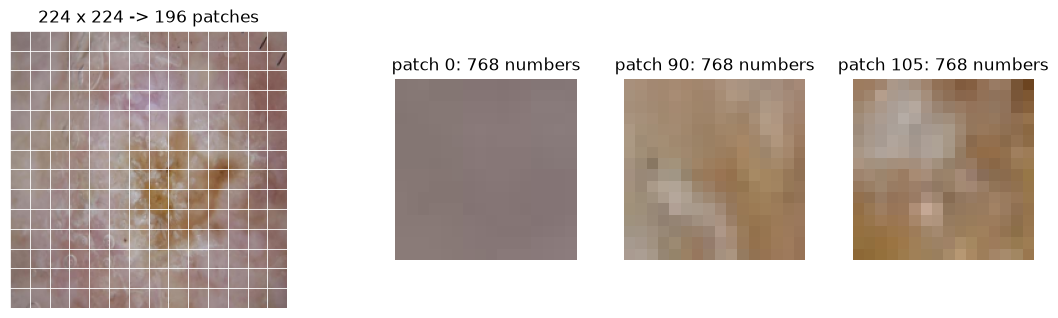

In [6]:
# PURPOSE: see the patch grid, and three patches the way the model receives them.
# HOW: draw a line every 16 pixels; show patches 0, 90 and 105 on their own.

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), gridspec_kw={"width_ratios": [2.2, 1, 1, 1]})
axes[0].imshow(lesion)
for k in range(0, 225, 16):
    axes[0].axhline(k - 0.5, color="white", lw=0.6)
    axes[0].axvline(k - 0.5, color="white", lw=0.6)
axes[0].set_title("224 x 224 -> 196 patches")
for ax, k in zip(axes[1:], [0, 90, 105]):
    ax.imshow(patches[k].reshape(16, 16, 3))
    ax.set_title(f"patch {k}: 768 numbers")
for ax in axes:
    ax.axis("off")

### 2. Attention from scratch · *slides 11–12*

**Attention(Q, K, V) = softmax(Q Kᵀ / √d) · V**, in four steps: compare, scale, softmax, mix.

#### ✏️ Exercise 2 — `attention` 

Write `attention(Q, K, V)` with NumPy. `Q`, `K`, `V` have one row per token and `d` columns.

1. **compare + scale:** `scores = Q @ K.T / np.sqrt(d)`, with `d = Q.shape[1]`
2. **softmax per row:** `weights = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)`
3. **mix:** `output = weights @ V`

Return `output, weights`. The check uses the slide's example: tokens A = [1, 0], B = [0, 1], C = [1, 1].

In [7]:
def attention(Q, K, V):
    """Scaled dot-product attention. Returns (output, weights)."""
    d = Q.shape[1]
    scores = Q @ K.T / np.sqrt(d)
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    weights = exp_scores / exp_scores.sum(axis=1, keepdims=True)
    output = weights @ V
    return output, weights

In [8]:
# CHECK Exercise 2 — slide 12: Q = K = V = X
X = np.array([[1., 0.],      # token A
              [0., 1.],      # token B
              [1., 1.]])     # token C
out, w = attention(X, X, X)
ok = w is not None
check("each row of weights adds up to 1", ok and np.allclose(w.sum(axis=1), 1))
check("row C of weights = [0.248, 0.248, 0.503]", ok and np.allclose(w[2], [0.248, 0.248, 0.503], atol=1e-3))
check("output of C = [0.752, 0.752]", ok and np.allclose(out[2], [0.752, 0.752], atol=1e-3))

# the same formula as PyTorch's built-in version, on 196 random tokens
rng = np.random.default_rng(0)
Q, K, V = (rng.normal(size=(196, 64)) for _ in range(3))
torch_out = F.scaled_dot_product_attention(*(torch.tensor(a) for a in (Q, K, V))).numpy()
check("same as PyTorch on 196 tokens", ok and np.allclose(attention(Q, K, V)[0], torch_out))

✅ each row of weights adds up to 1
✅ row C of weights = [0.248, 0.248, 0.503]
✅ output of C = [0.752, 0.752]
✅ same as PyTorch on 196 tokens


#### 2.1 Attention does not know the order · *slide 16*

We shuffle the tokens: the outputs come out shuffled the same way, with the **same values**. That's why a ViT must add a **position embedding**.

In [9]:
# PURPOSE: show that attention ignores the order of its input tokens.
# HOW: shuffle the 196 tokens, run attention again, compare with the shuffled original output.

perm = rng.permutation(196)
out_original, _ = attention(Q, K, V)
out_shuffled, _ = attention(Q[perm], K[perm], V[perm])
print("same values, just in another order:", np.allclose(out_shuffled, out_original[perm]))   # True

same values, just in another order: True


### 3. Inside a pretrained ViT-B/16 · *slides 15, 18, 19*

**ViT-B/16** = ViT-**B**ase with **16**×16 patches, pretrained on ImageNet. The first time, torchvision downloads it (330 MB).

In [10]:
# PURPOSE: load ViT-B/16 and look at its main parts.
# HOW: the same torchvision code as resnet18 in Session 7.

from torchvision.models import vit_b_16, ViT_B_16_Weights

vit = vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1).eval()
n_weights = sum(p.numel() for p in vit.parameters())
print(f"{n_weights:,} weights")                     # 86,567,656 (ResNet-18: 11,689,512)
print(vit.conv_proj)                                # Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
print(len(vit.encoder.layers), "encoder blocks")    # 12

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to C:\Users\Kinjal Chatterjee/.cache\torch\hub\checkpoints\vit_b_16-c867db91.pth


100.0%


86,567,656 weights
Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
12 encoder blocks


#### ✏️ Exercise 3 — follow one image through the ViT

Complete the three missing lines (`None`). Each comment gives the expected shape.

1. After the patch embedding (a convolution), `h` is (1, 768, 14, 14). Make it a **list of 196 tokens**: `h.flatten(2).transpose(1, 2)` → (1, 196, 768).
2. Put the **class token** in front: `torch.cat([vit.class_token, h], dim=1)` → (1, 197, 768).
3. After the encoder, only the **class token** (position 0) goes to the head: `vit.heads(z[:, 0])` → (1, 1000).

`vit.encoder` adds the position embedding and runs the 12 blocks for us.

In [11]:
x = prep(X_val[:1])
with torch.no_grad():
    h = vit.conv_proj(x)
    h = h.flatten(2).transpose(1, 2)
    h = torch.cat([vit.class_token.expand(h.shape[0], -1, -1), h], dim=1)
    z = vit.encoder(h)
    logits = vit.heads(z[:, 0])

In [12]:
# CHECK Exercise 3
check(f"tokens + class token: (1, 197, 768) -> got {None if h is None else tuple(h.shape)}", h is not None and tuple(h.shape) == (1, 197, 768))
check(f"output of the head: (1, 1000) -> got {None if logits is None else tuple(logits.shape)}", logits is not None and tuple(logits.shape) == (1, 1000))
with torch.no_grad():
    check("your steps give exactly vit(x)", logits is not None and torch.allclose(logits, vit(x), atol=1e-4))

✅ tokens + class token: (1, 197, 768) -> got (1, 197, 768)
✅ output of the head: (1, 1000) -> got (1, 1000)
✅ your steps give exactly vit(x)


#### 3.1 A real attention map · *slide 21* (just run it)

Where does the class token look in the last block? torchvision computes these weights but doesn't return them, so this cell asks for them for a moment. Bright = more attention. Remember: this ViT learned on everyday photos, not on lesions.

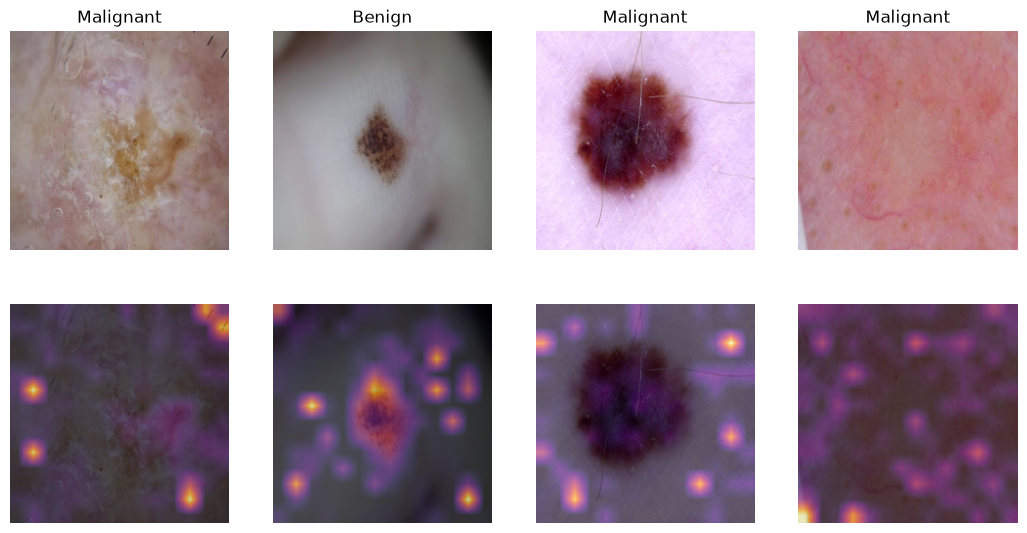

In [13]:
# PURPOSE: show the class token's attention over the 196 patches, on 4 lesions.
# HOW: temporarily make the last attention layer return its weights, then put it back as it was.

def cls_attention(images):
    layer = vit.encoder.layers[-1].self_attention
    original_forward, saved = layer.forward, {}
    def forward_with_weights(q, k, v, **kwargs):
        kwargs["need_weights"] = True                    # ask for the weights (torchvision says False)
        out, weights = original_forward(q, k, v, **kwargs)
        saved["w"] = weights                             # (batch, 197, 197), averaged over the 12 heads
        return out, weights
    layer.forward = forward_with_weights
    with torch.no_grad():
        vit(prep(images))
    layer.forward = original_forward                     # back to normal
    return saved["w"][:, 0, 1:].reshape(-1, 14, 14)      # row of the class token, without itself

idx = [0, 3, 8, 21]
att = cls_attention(X_val[idx])
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for j, i in enumerate(idx):
    big = F.interpolate(att[j][None, None], size=224, mode="bilinear")[0, 0]     # 14x14 -> 224x224
    axes[0, j].imshow(X_val[i].permute(1, 2, 0)); axes[0, j].set_title(CLASSES[y_val[i]])
    axes[1, j].imshow(X_val[i].permute(1, 2, 0)); axes[1, j].imshow(big, cmap="inferno", alpha=0.6)
for ax in axes.ravel():
    ax.axis("off")

### 4. A ViT next to a CNN, in a fair way · *slides 23, 25*

Same lesions, **same head**, same training, same metric: only the backbone changes. Both backbones are **frozen**: we turn every lesion into a vector once (ResNet-18: 512 numbers, ViT: 768), then train only a new last layer.

#### 4.1 Compute the features once (the slow step)

About **5–10 minutes** in class (`FULL = False`), 20–30 at home with `FULL = True`. The result is saved in `WORK_DIR`: the next time, it loads in a second.

In [14]:
# PURPOSE: turn every lesion into one vector per backbone.
# HOW: remove each network's last layer, run all images once without gradients, save the result.

from torchvision.models import resnet18, ResNet18_Weights

def backbone(name):
    if name == "resnet18":
        net = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        net.fc = nn.Identity()                    # output: 512 numbers instead of 1000 classes
    else:
        net = vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1)
        net.heads = nn.Identity()                 # output: the class token, 768 numbers
    return net.eval()

def features(name, X, split):
    f = WORK_DIR / f"s9_features_{name}_{split}_{len(X)}.pt"
    if not f.exists():
        net, t0 = backbone(name), time.perf_counter()
        with torch.no_grad():
            out = torch.cat([net(prep(X[i:i + 64])) for i in range(0, len(X), 64)])   # 64 images at a time
        torch.save(out, f)
        print(f"{name} {split}: {tuple(out.shape)} in {time.perf_counter() - t0:.0f} s")
    return torch.load(f)

feats = {name: {"train": features(name, X_train, "train"), "val": features(name, X_val, "val")}
         for name in ["resnet18", "vit_b_16"]}
print({name: tuple(f["train"].shape) for name, f in feats.items()})    # resnet18 (1000, 512), vit_b_16 (1000, 768)

resnet18 train: (1000, 512) in 17 s
resnet18 val: (599, 512) in 10 s
vit_b_16 train: (1000, 768) in 198 s
vit_b_16 val: (599, 768) in 193 s
{'resnet18': (1000, 512), 'vit_b_16': (1000, 768)}


#### ✏️ Exercise 4 — the same head for both 

`train_head` trains one `nn.Linear` on the features: the same recipe as Session 7 (class weights, Adam, 25 epochs).

1. Complete the **4 lines of the training step** (Session 6): forget the old gradients, compute the loss, backpropagation, update the weights.
2. Complete `macro_f1`: predict the class with the highest score (`.argmax(1)`), then `f1_score(..., average="macro")`.

In [15]:
def train_head(F_train, y, n_classes=3, epochs=25):
    torch.manual_seed(0)
    head = nn.Linear(F_train.shape[1], n_classes)
    class_weights = len(y) / (n_classes * torch.bincount(y, minlength=n_classes).float())
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
    for epoch in range(epochs):
        order = torch.randperm(len(y))
        for i in range(0, len(y), 64):
            idx = order[i:i + 64]
            optimizer.zero_grad()
            logits = head(F_train[idx])
            loss = loss_fn(logits, y[idx])
            loss.backward()
            optimizer.step()
    return head

def macro_f1(head, F_, y):
    with torch.no_grad():
        pred = head(F_).argmax(1)
    return float(f1_score(y.cpu().numpy(), pred.cpu().numpy(), average="macro"))

In [16]:
# CHECK Exercise 4 — train both heads and score them on the same 599 validation lesions
heads, val_f1 = {}, {}
for name in ["resnet18", "vit_b_16"]:
    heads[name] = train_head(feats[name]["train"], y_train)
    val_f1[name] = macro_f1(heads[name], feats[name]["val"], y_val)
    print(f"{name:9s} validation macro-F1 = {val_f1[name]:.3f}" if val_f1[name] is not None else f"{name}: macro_f1 not done yet")
ok = all(isinstance(v, float) for v in val_f1.values())
check("both heads trained and scored", ok)
check("both clearly better than chance (macro-F1 > 0.4)", ok and min(val_f1.values()) > 0.4)

resnet18  validation macro-F1 = 0.587
vit_b_16  validation macro-F1 = 0.575
✅ both heads trained and scored
✅ both clearly better than chance (macro-F1 > 0.4)


#### 4.2 Where are the errors?

Same validation lesions, rows = truth, columns = prediction. Look at the small **Indeterminate** row: that's where macro-F1 is won or lost.

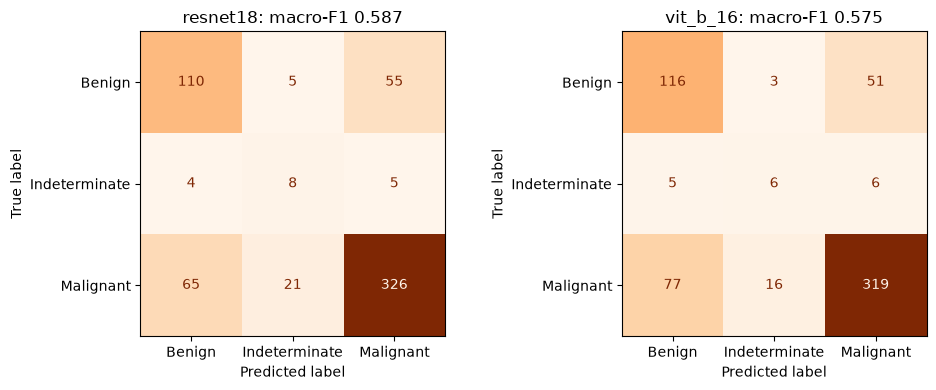

In [17]:
# PURPOSE: compare the errors of the two backbones, class by class.
# HOW: one confusion matrix per backbone, side by side.

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["resnet18", "vit_b_16"]):
    with torch.no_grad():
        pred = heads[name](feats[name]["val"]).argmax(1)
    ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=CLASSES, cmap="Oranges", ax=ax, colorbar=False)
    ax.set_title(f"{name}: macro-F1 {val_f1[name]:.3f}")
plt.tight_layout()

### 5. For your project (Milestone 4)

- Do the same with **your** CNN and a ViT: **same split, same target (3 or 11 classes), same head, same metric**.
- Choose the better one **on validation**; use your test set **once**, at the end.
- With `FULL = True` you use all your training lesions. Keep the saved features: next session you retrain the head with **11 outputs** for the leaderboard in seconds.
- Your numbers will be different from your classmates': that's normal, the comparison is what counts.